# **Community Detection in the Karate Club Graph Using Modularity**

## Research Assignment - DSC 212

### Tushar Tibude (IMS25312)
24th November, 2026

In [ ]:
!python --version

Python 3.13.18


In [ ]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

## **We obtain the Karate Club Dataset and plot it to demonstrate connections**

Graph has 34 nodes, 78 edges, is undirected and we override pre-existing edge weights and set them to 1 for this analysis. This is important for adjacency matrix symmetry and keeps things simple.

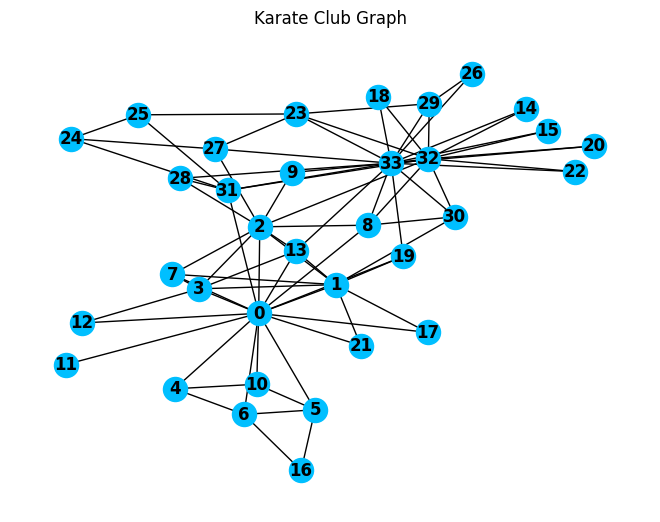

In [ ]:
G = nx.karate_club_graph()
# Graph is weighted by default, set it to 1
nx.set_edge_attributes(G, 1, 'weight')

layout_seed = 67

nx.draw(G, pos=nx.spring_layout(G, seed=layout_seed), with_labels=True, node_color="deepskyblue", font_weight="bold")
plt.title("Karate Club Graph")
plt.show()

## **Getting Parameters**

The parameters we are interested in are:
- $\mathbf{A}$ - Adjacency matrix of given graph or sub graph
- $\mathbf{B}$ - Modularity matrix of the original graph $G$
- $\mathbf{\tilde{B}^{(C)}}$ - Generalized restricted modularity matrix of some sub graph $G_i$

Notation used in code:
- `G`, `A`, `B` - Describe parameters (`networkx` graph, adjacency matrix, modularity matrix) for the original karate club graph $G$.
- `Gi`, `Ai`, `Bci` - Describe same general parameters for obtained sub graphs after partioning, where `Bci` is the generalized restricted modularity matrix $\mathbf{\tilde{B}^{(C)}}$.

**Note**:
<br>Generalized matrix is obtained from restricted matrix by formula:
<br>$\mathbf{\tilde{B}^{(C)}} = \mathbf{B^{(C)}} - diag(\mathbf{B^{(C)} 1})$
<br>This is done to preserve row sum property .

In [ ]:
def get_adjacency(Gi):
  Ai = nx.to_numpy_array(Gi)    # (P, P)
  return Ai

def get_modularity(G):
  # Obtain adjacency matrix as NxN numpy array where N
  # is the no. of nodes
  A = get_adjacency(G)

  # Construct degree matrix and its transpose
  # Convert node dictionary to index list
  d = dict(G.degree)

  # Sum of degrees of vertices = 2m, where m = no. of edges
  m = sum(list(d.values()))/2

  # NOTE: Relies on the assumption that dictionaries are ordered (python 3.7+)
  kT = np.array([list(d.values())])   # (1, N)
  k = kT.T                      # (N, 1)

  # Get modularity matrix
  B = A - (k@kT)/(2*m)

  return B

def get_restricted_modularity(Gi, A):
  # A is the original graph adjacency matrix
  # Gi is any sub divided graph component of it
  # Assuming Gi has P vertices, B(C) is returned where C
  # is the community represented by Gi and is of dimension PxP
  P = len(Gi)
  m = A.sum()/2

  Bci = np.zeros((P, P))

  for i1, n1 in enumerate(list(Gi.nodes)):
    k1 = np.sum(A[n1])
    for i2, n2 in enumerate(list(Gi.nodes)[i1+1:], start=i1+1):
      k2 = np.sum(A[n2])

      v = A[n1][n2] - (k1*k2)/(2*m)
      Bci[i1][i2] = v
      Bci[i2][i1] = v

    Bci[i1][i1] = -(k1*k1)/(2*m)

  Bci = Bci - np.diag(Bci.sum(axis=1))

  return Bci


## **Partition Function**

For some given graph or sub graph $G$, we have a function that given its restricted modularity matrix $\mathbf{B^{(C)}}$, it checks if a partition is possible by evaluating the delta modularity score $\Delta Q$. If the score is near $0$ or negative then it doesn't partition as it implies decrease or no increase in quality.

**Note**: Near 0 is taken into account with a threshold value of $10^{-5}$ to avoid floating point values very close to $0$.

In [ ]:
# Soft split (-1, +1) to hard split {-1, +1}
def hard_split(x):
  if x > 0:
    return 1
  else:
    return -1

def partition_if_viable(Gi, Bci, m):
  # Gi is the (sub)graph, Bci is the generalized modularity matrix
  # for this (sub)graph

  #print("Trying ", Gi)
  if len(Gi) <= 1:
    return False, False, False

  # Get adjacency matrix for (sub)graph
  Ai = get_adjacency(Gi)
  evals, evecs = np.linalg.eigh(Bci)

  # Find maximum eigenvalue
  max_eval_i = np.argmax(evals)
  max_eval = evals[max_eval_i]

  max_evec = evecs[:, max_eval_i]
  # Obtain partition list
  s = [hard_split(x) for x in max_evec]

  S = np.array([s])
  # Calculate modularity score for this partition
  Q = (S@Bci@S.T)/(4*m)

  # Clamp Q to 0 if its too low to avoid barely positive
  # floating point noise
  if abs(Q) < 1e-5:
    Q = 0

  if Q <= 0:
    # Partitioning doesn't change or makes community split deviate from NULL
    # So we dont partition
    return False, False, False

  Gi1 = nx.Graph() # -1
  Gi2 = nx.Graph() # +1

  for i1, n1 in enumerate(list(Gi.nodes)):
    group_n1 = s[i1]
    if group_n1 == -1:
      Gi1.add_node(n1)
    else:
      Gi2.add_node(n1)

    for i2, n2 in enumerate(list(Gi.nodes)[i1+1:], start=i1+1):
      group_n2 = s[i2]
      con = Ai[i1][i2]

      if group_n1 == group_n2 and con == 1:
        # Same group and connected

        if group_n1 == -1:
            Gi1.add_edge(n2, n1, weight=1)
        else:
            Gi2.add_edge(n2, n1, weight=1)

  return Gi1, Gi2, Q

## **Recursive modularity partitioning algorithm**

Once a single graph or sub graph can be partitioned and checked, we use this
function inside a recursive algorithm that keeps partitioning until a bottom is reached ($\Delta Q \approx 0$) or we hit `max_depth` in recursion (where each level down increases `depth` by 1).
<br><br>
This is done along for each partition as newly created sub graphs are added to the `C` (Community) list, and the old graph that was subdivided is removed. Additionally, we keep track of change of this `C` list by incrementing copies to the `C_timeline` list, to make state viewing and metric extraction possible.

In [ ]:
def recursive_modularity_partition(C, C_timeline, Gi, Bi, A, depth=1, maxdepth=10):
  m = A.sum()/2
  Gi1, Gi2, Q = partition_if_viable(Gi, Bi, m)

  # Cant partition anymore
  if Gi1 == False:
    print("(end - bottom)")
    return

  # Partition has been obtained, now build 2 new sub graphs (partitions)
  # that preserve within partition connections through adjacency matrix while
  # breaking others
  # Add them to community list and remove old
  C.append(Gi1)
  C.append(Gi2)

  if Gi in C:
    C.remove(Gi)

  # Preserve this split in timeline
  C_timeline.append(C.copy())

  # Try recursive sub partition
  Bi1 = get_restricted_modularity(Gi1, A)
  Bi2 = get_restricted_modularity(Gi2, A)

  if maxdepth == depth:
    print(" "*depth, Gi1, f"Q:{Q}", "(end - max depth)")
    print(" "*depth, Gi2, f"Q:{Q}", "(end - max depth)")
  else:
    print(" "*depth, Gi1, f"Q:{Q}")
    recursive_modularity_partition(C, C_timeline, Gi1, Bi1, A, depth=depth+1, maxdepth=maxdepth)
    print(" "*depth, Gi2, f"Q:{Q}")
    recursive_modularity_partition(C, C_timeline, Gi2, Bi2, A, depth=depth+1, maxdepth=maxdepth)


## **Calculating metrics through timeline data**

We evaluate the following metrics for each iteration, for each node in the overall graph. Starting from the unpartitioned initial graph, over all stages up until final partition.

- **Degree Centrality** ($C_D$)
- **Betweennness Centrality** ($B_D$)
- **Closeness Centrality** ($C_C$)
- **Clustering Coefficient** ($C_K$)

In [ ]:
def get_metrics(G, C_timeline):
  metrics = {}
  metrics[0] = {"D":{}, "B":{}, "C":{}, "K":{}}

  # Initial state
  d = nx.degree_centrality(G)
  b = nx.betweenness_centrality(G)
  c = nx.closeness_centrality(G)
  k = nx.clustering(G)
  metrics[0]["D"][0] = d
  metrics[0]["B"][0] = b
  metrics[0]["C"][0] = c
  metrics[0]["K"][0] = k

  for Ci, C in enumerate(C_timeline):
    # Community list will have each node exactly once, in some group

    # D - Degree Centrality
    # B - Betweenness Centrality
    # C - Closeness Centrality
    # K - Clustering Coefficient
    metrics[Ci+1] = {"D":{}, "B":{}, "C":{}, "K":{}}

    for Gi, G in enumerate(C):
      """
      skip = False
      if Ci > 0:
        # Add metric only if the graph has changed across
        # iteration, or it was sitting stale and not being operated on so skip
        for prev in C_timeline[Ci-1]:
          if nx.utils.graphs_equal(Gi, prev):
            skip = True
            break

      if skip:
        continue
      """
      d = nx.degree_centrality(G)
      b = nx.betweenness_centrality(G)
      c = nx.closeness_centrality(G)
      k = nx.clustering(G)
      metrics[Ci+1]["D"][Gi] = d
      metrics[Ci+1]["B"][Gi] = b
      metrics[Ci+1]["C"][Gi] = c
      metrics[Ci+1]["K"][Gi] = k

  return metrics

## **Plotting results for the Karate Club graph**

<h4>After running the recursive algorithm on the Karate Club graph and plotting all metrics on a bar plot partion wise. <br>We obtain the following results: </h4>


## **Note**:
<h4>Graphs are visualized with the original graph being colour coded with parted communities, the edges between them have not been removed in this visualization. But metric calculations were done individually for communities (after removal of any out of community edges).</h4>

  Graph with 18 nodes and 35 edges Q:[[0.37146614]]
   Graph with 6 nodes and 7 edges Q:[[0.02071006]]
(end - bottom)
   Graph with 12 nodes and 21 edges Q:[[0.02071006]]
(end - bottom)
  Graph with 16 nodes and 33 edges Q:[[0.37146614]]
   Graph with 9 nodes and 13 edges Q:[[0.00123274]]
(end - bottom)
   Graph with 7 nodes and 11 edges Q:[[0.00123274]]
(end - bottom)


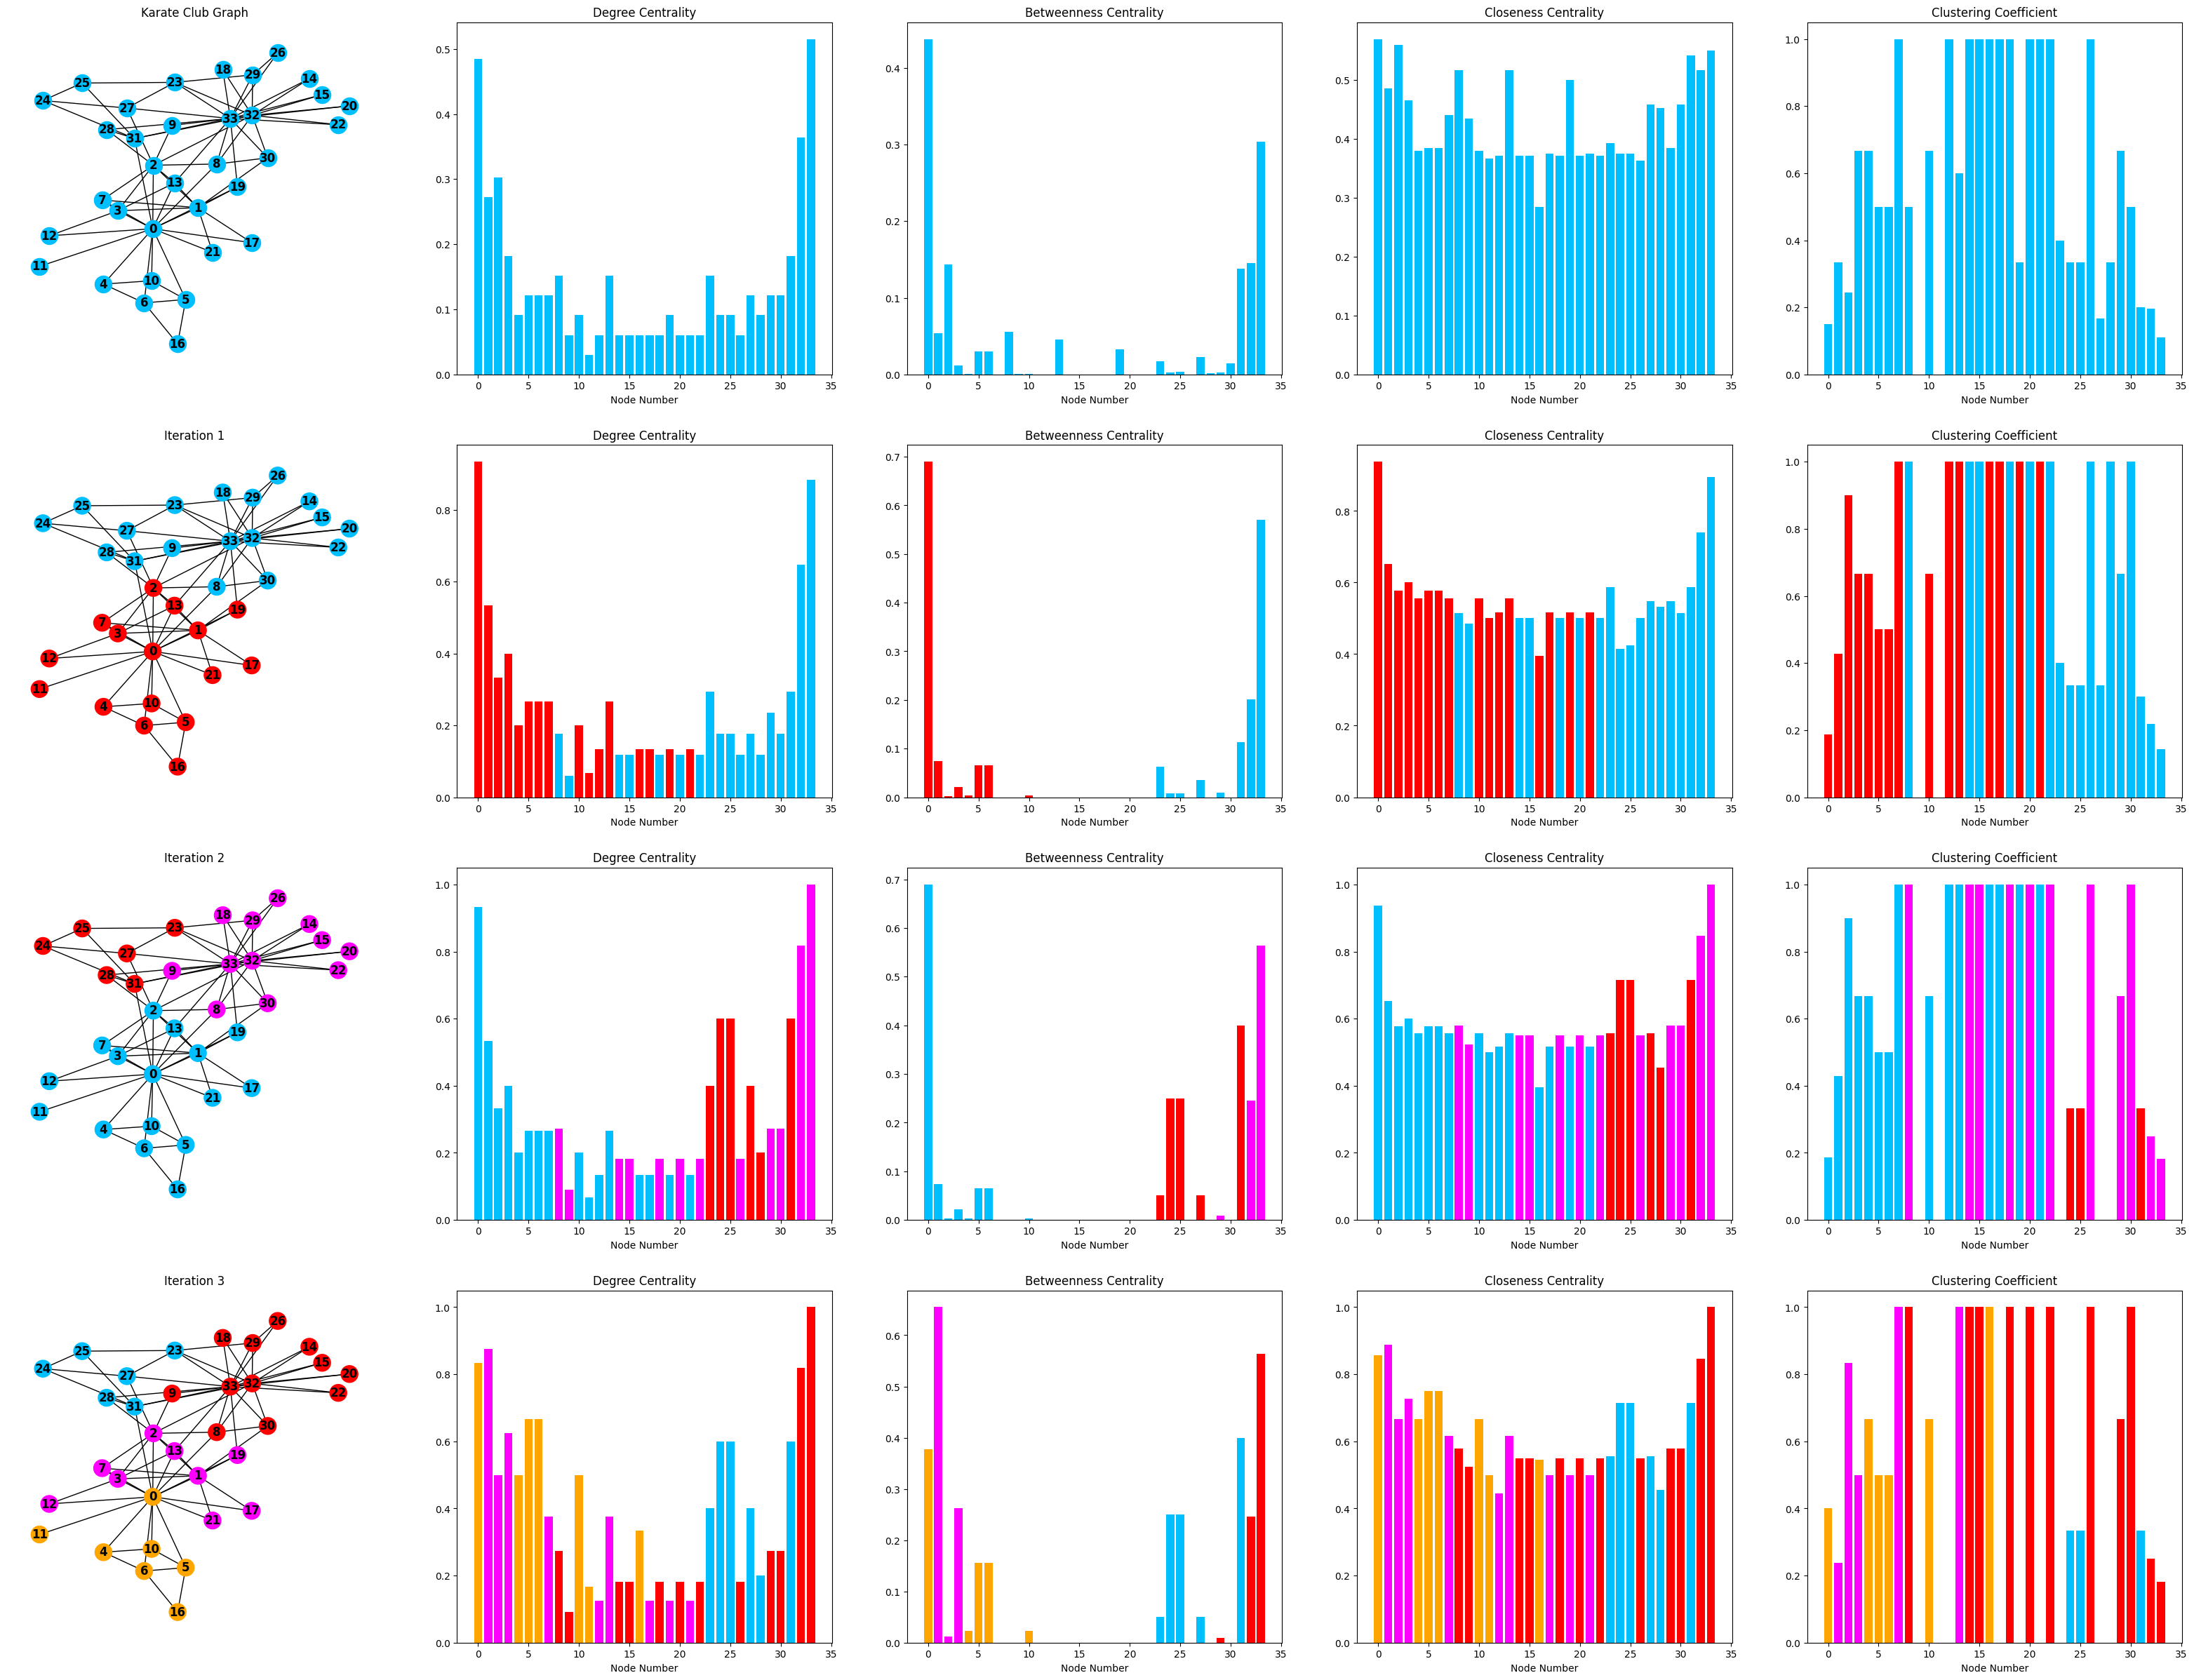

In [ ]:
colors = ["deepskyblue", "red", "magenta", "orange"]

# Final list of partitioned communities
C = []
# Timeline metadata
C_timeline = []

A = get_adjacency(G)
B = get_modularity(G)

recursive_modularity_partition(C, C_timeline, G, B, A, maxdepth=10)

metrics = get_metrics(G, C_timeline)

# Create a nx1 grid of subplots
fig, axes = plt.subplots(nrows=len(C), ncols=5, figsize=(40, 30))

axes[0][0].set_title("Karate Club Graph")
nx.draw(G, pos=nx.spring_layout(G, seed=layout_seed), ax=axes[0][0], with_labels=True, node_color="deepskyblue", font_weight="bold")

for Ci, C in enumerate(C_timeline):
  color_map = []

  for i in range(len(G)):
    for j in range(len(C)):
      if i in C[j]:
        color_map.append(colors[j])
        break

  axes[Ci+1][0].set_title(f"Iteration {Ci+1}")
  nx.draw(G, pos=nx.spring_layout(G, seed=layout_seed), ax=axes[Ci+1][0], with_labels=True, node_color=color_map, font_weight="bold")

for it, M in metrics.items():


  plots = {"D":"Degree Centrality", "B":"Betweenness Centrality", "C":"Closeness Centrality", "K":"Clustering Coefficient"}

  for name_i, name in enumerate(plots.keys()):
    ax = axes[it][name_i+1]

    for Gi, d in M[name].items():
      cats = d.keys()
      vals = d.values()
      ax.set_title(plots[name])
      ax.set_xlabel("Node Number")

      ax.bar(cats, vals, color=colors[Gi])

plt.show()


# **Discussion**
The graph splits into $4$ communities before stabilizing ($\Delta Q \approx 0$), using the recursive modularity algorithm. <br>

Primarily node numbers $0, 1, 31, 32, 33$ consistently remain central before and after the splits. These act as strong hubs and connectors in the original graph (high Betweenness Centrality), have high no. of nodes connected to them in absolute terms (high Degree Centrality), they can reach other nodes quickly and have low average shortest path distance (high Closeness Centrality), and maintain their role after subsequent community partioning which is the primary reason for this observation.
<br><br>
They also have low Clustering Coefficient compared to other nodes as due to having high no. of connected nodes and centrality, the likelihood of its connected nodes being connected to each other decreases.

# **References**

Methodology:<br>
<i>Newman (2006), “Modularity and community structure in
networks,” PNAS 103(23):8577–8582.

# **AI Usage Disclosure**

AI was used for bridging gaps in understanding of modularity and community detection theory. <br>
No AI was used for problem solving, writing code or plot generation.